# Imports

In [1]:
#import pytorch - for computing tensors
import torch, gc 
#import transformers - for accessing pre-trained models, tokenizers,training and evaluation
from transformers import (
    GPTNeoForCausalLM,
    GPT2Tokenizer
)
from torch.utils.data import DataLoader
import math
import matplotlib.pyplot as plt
from itertools import chain
from tqdm import tqdm
import my_dataset
from transformers import DataCollatorForLanguageModeling
import numpy as np
import wandb

/scratch/storage0/ce20b049/miniconda3/envs/venv_HW2_Q5/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Model

In [2]:
gc.collect()
torch.cuda.empty_cache()
device = torch.device("cuda:2")
tokenizer = GPT2Tokenizer.from_pretrained("EleutherAI/gpt-neo-125M")
tokenizer.pad_token = tokenizer.eos_token
model = GPTNeoForCausalLM.from_pretrained("EleutherAI/gpt-neo-125M")
model.config.pad_token_id = tokenizer.eos_token_id
model.to(device)

GPTNeoForCausalLM(
  (transformer): GPTNeoModel(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(2048, 768)
    (drop): Dropout(p=0.0, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPTNeoBlock(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPTNeoAttention(
          (attention): GPTNeoSelfAttention(
            (attn_dropout): Dropout(p=0.0, inplace=False)
            (resid_dropout): Dropout(p=0.0, inplace=False)
            (k_proj): Linear(in_features=768, out_features=768, bias=False)
            (v_proj): Linear(in_features=768, out_features=768, bias=False)
            (q_proj): Linear(in_features=768, out_features=768, bias=False)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPTNeoMLP(
          (c_fc): Linear(in_features=768, out_features=3072, bias=True)
          (c_proj): Linear(in_fe

In [3]:
from torchvision import datasets #To load dataset
from datasets import Dataset, DatasetDict
import datasets
from datasets import load_dataset
import pandas as pd

# Load the dataset
def get_dataset(canary,num,ratio=0.005, shuffle=True):
    dataset_all = load_dataset("zicsx/Wikipedia-Hindi", split="train")
    sub_dataset = dataset_all.select(range(int(ratio * len(dataset_all)))) # no shuffling. Exact same examples selected every time

    split_ratio = 0.1 
    train_test_split = sub_dataset.train_test_split(test_size=split_ratio, seed=42)

    dataset = DatasetDict({
        'train': train_test_split['train'],
        'validation': train_test_split['test']
    })
    train_df = pd.DataFrame(dataset["train"])
    print(train_df.head(5))

    return dataset

# Preprocessing Data

## Tokenization

In [4]:
def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, return_special_tokens_mask=True)

In [5]:
def get_canary_tokens(canary):
    input_ids=tokenizer(canary,truncation=True,return_special_tokens_mask=True)
    print(input_ids)
    return input_ids

In [6]:
def get_example_indices(total,num,shuffle=False):
    if shuffle==True:
        return np.random.choice(total, size=num, replace=False)
    else:
        return np.arange(0,num)

## Grouping into Blocks

In [7]:
block_size=256
run=True
def group_texts(examples,canary,num,shuffle):
    # Concatenate all texts.
    global run 
    concatenated_examples = {k: list(chain(*examples[k])) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    # We drop the small remainder, and if the total_length < block_size  we exclude this batch and return an empty dict.
    # We could add padding if the model supported it instead of this drop, you can customize this part to your needs.
    total_length = (total_length // block_size) * block_size
    # Split by chunks of max_len.
    result = {
        k: [t[i : i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated_examples.items()
    }
    print(total_length//block_size)

    if(total_length//block_size>1000):
        print("called")
        result["indicators"] = [0 for _ in range(total_length//block_size)]
        ind=get_example_indices(total_length//block_size,num,shuffle)
        print(ind)
        ans=get_canary_tokens(canary=canary)
        length=len(ans['input_ids'])
        for j in ind:
            for key in result.keys():
                if(key=="indicators"):
                    continue
                for i in range(length):
                    result[key][j][i]=ans[key][i]
            result["indicators"][j]=1
        run=False
    else:
        run=True
    result["labels"] = result["input_ids"].copy()
    return result

# Dataloaders

In [8]:
def get_dataloaders(tokenized_datasets,per_device_train_batch_size,per_device_eval_batch_size):
    train_dataset = tokenized_datasets["train"]
    train_dataset = train_dataset.select(range((len(train_dataset)//per_device_train_batch_size)*per_device_train_batch_size))
    eval_dataset = tokenized_datasets["validation"]
    data_collator = DataCollatorForLanguageModeling(
        tokenizer=tokenizer, mlm=False
    )
    train_dataloader = DataLoader(
        train_dataset, shuffle=False, collate_fn=data_collator, batch_size=per_device_train_batch_size
    )
    eval_dataloader = DataLoader(
        eval_dataset, collate_fn=data_collator, batch_size=per_device_eval_batch_size
    )
    return train_dataloader,eval_dataloader

# Calculate no. of steps

In [9]:
def get_steps(train_dataloader,max_train_steps=None,num_train_epochs=1):    
    num_update_steps_per_epoch = math.ceil(len(train_dataloader)) # per epoch training steps = len(train_dataloader)
    if max_train_steps is None:
        max_train_steps = num_train_epochs * num_update_steps_per_epoch # total number of training steps = no. of epochs*per epoch training steps
    print(f'No. of Training Steps = {max_train_steps}')
    print(f'No. of update steps per epoch = {num_update_steps_per_epoch}')

    return num_update_steps_per_epoch,max_train_steps

# Accuracy

In [10]:
def evaluate_model(dataloader):    
    model.eval()
    t_loss_sum = 0  # Sum of validation losses for the epoch
    total_t_correct = 0
    total_t_samples = 0

    with torch.no_grad():
        for step,batch in enumerate(dataloader):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            t_loss_sum += outputs.loss.item()

            # Get predictions and calculate validation accuracy
            pred = torch.argmax(outputs.logits, dim=2)
            label = batch["labels"]
            preds = torch.narrow(pred, dim=1, start=0, length=pred.size(1)-1)
            labels = torch.narrow(label, dim=1, start=1, length=label.size(1)-1)
            total_t_correct += (preds == labels).sum().item()
            total_t_samples +=  (labels==labels).sum().item()
            
            # print(f'batch={batch["input_ids"]}')
            # print(f'preds={preds}')
            # print(f'labels={labels}')
            # print(f'correct={total_t_correct}')
            # print(f'total={total_t_samples}')

    # Calculate average validation loss and accuracy for the epoch
    # avg_t_loss = t_loss_sum / len(dataloader)
    # t_perplexity = math.exp(avg_t_loss)
    t_accuracy = total_t_correct / total_t_samples

    # print(f""
    #     f"Average Loss = {avg_t_loss:.4f}, Accuracy = {t_accuracy * 100:.2f}%, ")
        # f"Train Perplexity = {t_perplexity:.2f}")
    
    return (t_accuracy*100)

# Training

In [11]:
def train_model(train_dataloader,eval_dataloader,learning_rate,num_epoch,T,n):
    
    weight_decay = 0.01    
    no_decay = ["bias", "layer_norm.weight"]
    optimizer_grouped_parameters = [
        {
            "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            "weight_decay": weight_decay,
        },
        {
            "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            "weight_decay": 0.0,
        },
    ]
    optimizer = torch.optim.AdamW(optimizer_grouped_parameters, lr=learning_rate)

    progress_bar = tqdm(range(T))
    completed_steps = 0

    acc=evaluate_model(dataloader=eval_dataloader)
    wandb.log({'Validation accuracy':acc,'Epoch':completed_steps/T*num_epoch},step=completed_steps)

    for epoch in range(num_epoch):
        model.train()
        for step, batch in enumerate(train_dataloader):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(input_ids=batch['input_ids'],labels=batch['labels'])
            loss = outputs.loss 
            wandb.log({'Training Loss':loss,'Epoch':completed_steps/T*num_epoch},step=completed_steps)
            loss.backward() # grad

            optimizer.step() # update
            optimizer.zero_grad()

            progress_bar.update(1)
            completed_steps += 1

            if completed_steps%(int(0.25*n))==0:
                acc=evaluate_model(dataloader=eval_dataloader)
                wandb.log({'Validation accuracy':acc,'Epoch':completed_steps/T*num_epoch},step=completed_steps)

                # acc=evaluate_model(dataloader=train_dataloader)
                # train_accuracy.append(acc)
    wandb.log({'Training Loss':loss,'Epoch':completed_steps/T*num_epoch},step=completed_steps)

# Exposure

In [12]:
def perplexity(canary):   
    inputs = tokenizer(canary, return_tensors="pt")
    inputs["labels"]=inputs["input_ids"]
    inputss = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputss)
        loss=outputs.loss
    perplexity = math.exp(loss)
    return perplexity

def get_all_canaries(n_dash):
    start=10**(n_dash-1)
    end=10**(n_dash)
    canaries=[]
    canary="My security number is "
    for i in range(start,end):
        canaries.append(canary+str(i))
    
    return canaries

def get_exposure(canary,n_dash):
    # print(canary)
    canaries=get_all_canaries(n_dash=n_dash)
    perplex=[]
    for c in canaries:
        p=perplexity(canary=c)
        perplex.append(p)
    for i in range(len(canaries)):
        if canaries[i]==canary:
            index=i
    t=np.argsort(perplex)
    rank=(np.where(t==index)[0][0])+1
    exposure=np.log2(10**(n_dash))-np.log2(rank)

    return exposure

# Run

In [13]:
num_epochs=1
lr=5e-4
batch_size = 16
batch_size_eval=4
nu=[0,2,4,8,16,32,64,128]
can='My security number is 412'
i=0
exp=[]
shuffle=True
for number in nu:
    print(f'--------------------No. of insertions = {number}--------------------')
    
    gc.collect()
    torch.cuda.empty_cache()
    device = torch.device("cuda:2")
    tokenizer = GPT2Tokenizer.from_pretrained("EleutherAI/gpt-neo-125M")
    tokenizer.pad_token = tokenizer.eos_token
    model = GPTNeoForCausalLM.from_pretrained("EleutherAI/gpt-neo-125M")
    model.config.pad_token_id = tokenizer.eos_token_id
    model.to(device)

    print('Loading the dataset...')
    dataset = my_dataset.get_dataset(canary=can,num=number, ratio=0.005)
    print(dataset)

    print('\n\nTokenizing the dataset...')
    tokenized_datasets = dataset.map(
        tokenize_function, batched=True, remove_columns=["text"]
    )

    print('\n\nGrouping the dataset...')
    tokenized_datasets = tokenized_datasets.map(group_texts, batched=True, fn_kwargs={"canary":can,"num":number,"shuffle":shuffle})
    print(f"Preprocessed data: {tokenized_datasets}")# After grouping, no. of rows in tokenised_datasets might change

    print('\n\nCreating Dataloaders...')
    train_dataloader,eval_dataloader = get_dataloaders(tokenized_datasets=tokenized_datasets,per_device_train_batch_size=batch_size,per_device_eval_batch_size=batch_size_eval)

    n,max_train_steps = get_steps(train_dataloader=train_dataloader,max_train_steps=None,num_train_epochs=num_epochs)

    print('\n\nTraining...')
    wandb.init(project="2_DPSGD - No of insertions", name=f'Num={number}, No DP',entity="ishita49-indian-institute-of-technology-madras")
    train_model(train_dataloader=train_dataloader, eval_dataloader=eval_dataloader, learning_rate=lr,num_epoch=num_epochs,T=max_train_steps,n=n)
    wandb.finish
    print('\n\nCalculating Exposure...')
    exposure=get_exposure(canary=can,n_dash=3)
    print(exposure)
    print('\n\n')
    exp.append(exposure)

--------------------No. of insertions = 0--------------------
Loading the dataset...
                                                text
0  वोल्फ़गांक आमडेयुस मोत्सार्ट (जर्मन: वॉल्फ्गंग...
1  ईरान () या ईरान इस्लामिक गणराज्य (, जम्हूरिए इ...
2  इम्फाल () भारत के मणिपुर राज्य की राजधानी है। ...
3  अब्दुर्रहीम ख़ान-ए-ख़ाना या रहीम, एक मध्यकालीन...
4  पन्थ/सम्प्रदाय के अर्थ में धर्म के लिए धर्म (प...
DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 696
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 78
    })
})


Tokenizing the dataset...


Grouping the dataset...


Map: 100%|██████████| 78/78 [00:00<00:00, 346.67 examples/s]

496
Preprocessed data: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'special_tokens_mask', 'attention_mask', 'indicators', 'labels'],
        num_rows: 4727
    })
    validation: Dataset({
        features: ['input_ids', 'special_tokens_mask', 'attention_mask', 'labels'],
        num_rows: 496
    })
})


Creating Dataloaders...
No. of Training Steps = 295
No. of update steps per epoch = 295


Training...



wandb: Currently logged in as: ishita49 (ishita49-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


100%|██████████| 295/295 [03:43<00:00,  1.32it/s]




Calculating Exposure...
0.4739311883324131



--------------------No. of insertions = 2--------------------
Loading the dataset...
                                                text
0  पाणिनि (७०० ई॰पू॰) संस्कृत भाषा के सबसे बड़े व...
1  म्हार मणिपुर और असम के पहाड़ी जिलों में रहने व...
2  कंगारू आस्ट्रेलिया में पाया जानेवाला एक स्तनधा...
3  गिरिडीह (गिरिडीह) भारत के झारखंड राज्य के गिरि...
4  फ़ारसी (), एक भाषा है जो ईरान, ताजिकिस्तान, अफ...
DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 698
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 78
    })
})


Tokenizing the dataset...


... (59 outputs left out)

Preprocessed data: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'special_tokens_mask', 'attention_mask', 'indicators', 'labels'],
        num_rows: 4729
    })
    validation: Dataset({
        features: ['input_ids', 'special_tokens_mask', 'attention_mask', 'labels'],
        num_rows: 496
    })
})


Creating Dataloaders...
No. of Training Steps = 295
No. of update steps per epoch = 295


Training...


Epoch,▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▇▇▇▇▇█████
Training Loss,█▃▃▂▂▂▂▂▂▃▂▂▂▂▂▂▂▂▂▁▂▂▂▂▂▁▁▁▁▁▂▁▁▁▂▁▁▁▁▁
Validation accuracy,▁▄▆▇█
Epoch,1
Training Loss,1.13358
Validation accuracy,66.10057


100%|██████████| 295/295 [03:43<00:00,  1.32it/s]




Calculating Exposure...
9.965784284662087





In [14]:
import wandb
nu=[0,1,2,4,8,16,32,64,128]
exp=[0.4739311883324131,9.965784284662087,9.965784284662087,9.965784284662087,9.965784284662087,9.965784284662087,9.965784284662087,9.965784284662087,9.965784284662087]
wandb.init(project="2_DPSGD - No of insertions", name=f'Exposure, No DP',entity="ishita49-indian-institute-of-technology-madras")
for i, (e, n) in enumerate(zip(exp, nu)):
    wandb.log({'Exposure': e, 'Number of insertions of Canary': math.log2(n) if n > 0 else None}, step=i)
wandb.finish()

Epoch,▁▁▂▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇█
Training Loss,█▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▁▁▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▂▁▁▁
Validation accuracy,▁▄▆▇█
Epoch,1
Training Loss,1.18892
Validation accuracy,66.39864


Exposure,▁████████
Number of insertions of Canary,▁▂▃▄▅▆▇█
Exposure,9.96578
Number of insertions of Canary,7


# Exposure vs No. of Insertions Plot

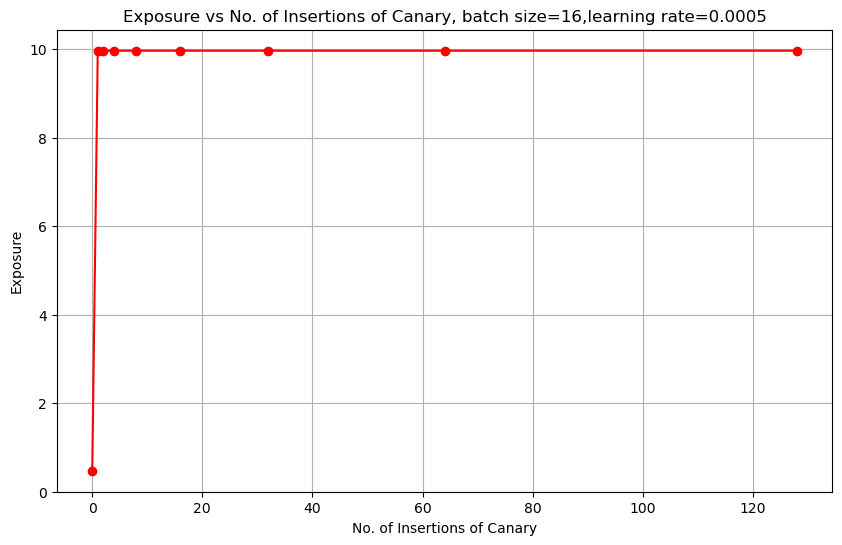

In [15]:
plt.figure(figsize=(10, 6))
plt.plot(nu,exp, marker='o', linestyle='-', color='r')
plt.title(f'Exposure vs No. of Insertions of Canary, batch size={batch_size},learning rate={lr}')
plt.xlabel('No. of Insertions of Canary')
plt.ylabel('Exposure')
plt.grid(True)
plt.show()

In [ ]:
import json
with open("exposure_NoDP.json", "w") as file:
    json.dump(exp, file)

: 